# GitHub activity of @cboulanger, 2005 to today

Contrasts yearly GitHub contributions in 2005–2022 with 2023 onward, to illustrate the effect of agentic coding.

**Data source.** By default the notebook reads the public contribution calendar
(`https://github.com/users/<login>/contributions?from=…&to=…`), which needs no token.
That number counts *contributions* (commits, pull requests, issues, reviews, new repos);
private contributions are included only if "Private contributions" is enabled on the profile.

If the environment variable `GITHUB_TOKEN` is set (a classic or fine-grained personal token with
`read:user`), the notebook instead queries the GraphQL API for `totalCommitContributions`, i.e. commits only,
including private ones the token can see. Run with `USE_CACHE=1` to skip the network and use `contributions.csv`.

In [1]:
import os, re, csv, datetime as dt
import requests
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

LOGIN = "cboulanger"
FIRST_YEAR, SPLIT_YEAR = 2005, 2023          # 2005–2022 vs. 2023 onward
TODAY = dt.date.today()
USE_CACHE = os.environ.get("USE_CACHE") == "1"   # reuse contributions.csv instead of fetching
CSV_PATH = "contributions.csv"
TOKEN = os.environ.get("GITHUB_TOKEN")

In [2]:
def calendar_total(year):
    """Total from the public contribution calendar ('N contributions in YEAR')."""
    url = f"https://github.com/users/{LOGIN}/contributions?from={year}-01-01&to={year}-12-31"
    html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
    m = re.search(r"([\d,]+)\s+contributions?\s+in\s+" + str(year), html)
    return int(m.group(1).replace(",", "")) if m else 0

def graphql_commits(year):
    """Commits only (needs GITHUB_TOKEN); restricted = private contributions not otherwise visible."""
    q = """query($login:String!,$from:DateTime!,$to:DateTime!){
      user(login:$login){contributionsCollection(from:$from,to:$to){
        totalCommitContributions restrictedContributionsCount}}}"""
    v = {"login": LOGIN, "from": f"{year}-01-01T00:00:00Z", "to": f"{year}-12-31T23:59:59Z"}
    r = requests.post("https://api.github.com/graphql", json={"query": q, "variables": v},
                      headers={"Authorization": f"bearer {TOKEN}"}, timeout=30)
    c = r.json()["data"]["user"]["contributionsCollection"]
    return c["totalCommitContributions"] + c["restrictedContributionsCount"]

if USE_CACHE and os.path.exists(CSV_PATH):
    with open(CSV_PATH) as f:
        rows = [(int(r["year"]), int(r["count"])) for r in csv.DictReader(f)]
    metric = "contributions"
else:
    fetch, metric = (graphql_commits, "commits") if TOKEN else (calendar_total, "contributions")
    rows = [(y, fetch(y)) for y in range(FIRST_YEAR, TODAY.year + 1)]
    with open(CSV_PATH, "w", newline="") as f:
        w = csv.writer(f); w.writerow(["year", "count", "metric", "period", "retrieved"])
        for y, n in rows:
            w.writerow([y, n, metric, "2005-2022" if y < SPLIT_YEAR else "2023-", TODAY.isoformat()])
rows

[(2005, 0),
 (2006, 0),
 (2007, 0),
 (2008, 0),
 (2009, 1),
 (2010, 1),
 (2011, 57),
 (2012, 63),
 (2013, 3),
 (2014, 307),
 (2015, 165),
 (2016, 24),
 (2017, 856),
 (2018, 1455),
 (2019, 1285),
 (2020, 1675),
 (2021, 1079),
 (2022, 688),
 (2023, 350),
 (2024, 240),
 (2025, 1031),
 (2026, 3390)]

In [3]:
before = [n for y, n in rows if y < SPLIT_YEAR]
after = [n for y, n in rows if y >= SPLIT_YEAR]
# The current year is partial: annualise it for the period mean only, the bar shows the real count.
frac = (TODAY - dt.date(TODAY.year, 1, 1)).days / 365
after_annual = after[:-1] + [after[-1] / frac]
active_before = [n for n in before if n > 0]   # ignore the empty years before the first activity
stats = {
    "mean/yr 2005–2022 (active years)": round(sum(active_before) / len(active_before)),
    f"mean/yr {SPLIT_YEAR}–{TODAY.year} (current year annualised)": round(sum(after_annual) / len(after_annual)),
    "peak before": max(before), f"{TODAY.year} so far": after[-1],
}
stats

{'mean/yr 2005–2022 (active years)': 547,
 'mean/yr 2023–2026 (current year annualised)': 1468,
 'peak before': 1675,
 '2026 so far': 3390}

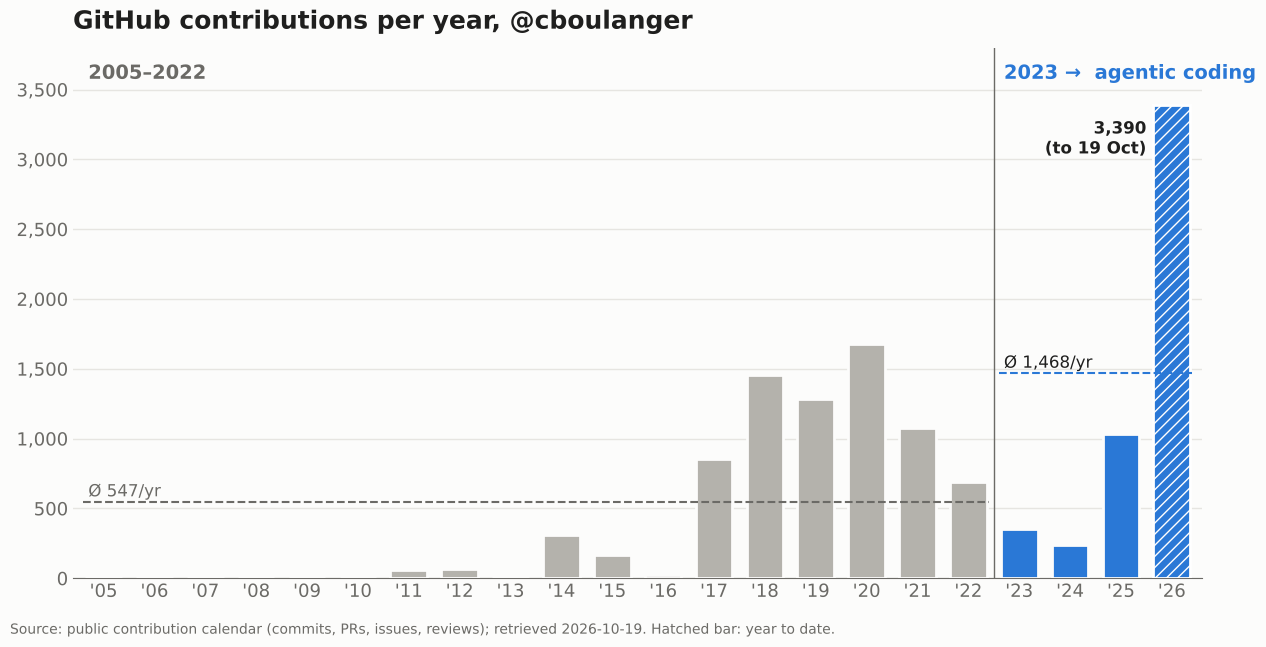

In [4]:
GRAY, BLUE, INK, MUTED, SURFACE = "#b4b2ac", "#2a78d6", "#1f1f1e", "#6b6a66", "#fcfcfb"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 13})

years = [y for y, _ in rows]; counts = [n for _, n in rows]
fig, ax = plt.subplots(figsize=(13, 6.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
colors = [GRAY if y < SPLIT_YEAR else BLUE for y in years]
bars = ax.bar(years, counts, width=0.72, color=colors, edgecolor=SURFACE, linewidth=2, zorder=3)
bars[-1].set_hatch("///"); bars[-1].set_edgecolor("white")   # partial year

# period means as dashed reference lines
m_before = stats["mean/yr 2005–2022 (active years)"]
m_after = list(stats.values())[1]
ax.hlines(m_before, years[0] - .4, SPLIT_YEAR - .6, color=MUTED, ls="--", lw=1.5, zorder=4)
ax.hlines(m_after, SPLIT_YEAR - .4, years[-1] + .4, color=BLUE, ls="--", lw=1.5, zorder=4)
ax.text(years[0] - .3, m_before + 40, f"Ø {m_before:,}/yr", ha="left", color=MUTED, fontsize=12)
ax.text(SPLIT_YEAR - .3, m_after + 40, f"Ø {m_after:,}/yr", ha="left", color=INK, fontsize=12)

# label only the latest bar
ax.text(years[-1] - .5, counts[-1] * .97, f"{counts[-1]:,}\n(to {TODAY:%d %b})", ha="right", va="top",
        color=INK, fontsize=12, fontweight="bold")

ax.axvline(SPLIT_YEAR - .5, color=MUTED, lw=1, zorder=2)
top = max(counts) * 1.12
ax.text(2005 - .3, top * .97, f"{FIRST_YEAR}–{SPLIT_YEAR - 1}", color=MUTED, fontsize=14, fontweight="bold", va="top")
ax.text(SPLIT_YEAR - .3, top * .97, f"{SPLIT_YEAR} →  agentic coding", color=BLUE, fontsize=14, fontweight="bold", va="top")

ax.set_ylim(0, top); ax.set_xlim(years[0] - .6, years[-1] + .6)
ax.set_xticks(years); ax.set_xticklabels([f"'{str(y)[2:]}" for y in years])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.grid(axis="y", color="#e6e5e1", lw=1, zorder=0)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(MUTED); ax.tick_params(colors=MUTED, length=0)
ax.set_title(f"GitHub {metric} per year, @{LOGIN}", loc="left", color=INK, fontsize=18, fontweight="bold", pad=14)
src = "public contribution calendar (commits, PRs, issues, reviews)" if metric == "contributions" else "GitHub GraphQL API, commit contributions incl. private"
fig.text(0.01, 0.01, f"Source: {src}; retrieved {TODAY:%Y-%m-%d}. Hatched bar: year to date.",
         color=MUTED, fontsize=10)
fig.tight_layout(rect=(0, 0.03, 1, 1))
for ext in ("svg", "png"):
    fig.savefig(f"commits-per-year.{ext}", dpi=200, facecolor=SURFACE)
plt.show()